# Robust Regression Engine

In [10]:
import warnings, json, joblib
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import (train_test_split, GridSearchCV, KFold, StratifiedKFold,
                                     LeaveOneOut, TimeSeriesSplit, cross_val_score, cross_validate, learning_curve)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, Lasso, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
sns.set_theme(style='whitegrid'); RS = 42
plt.rcParams['figure.dpi'] = 100

---
# Part A: Conceptual Foundation (Theory)

**1. What is Regularization in Machine Learning? Why is it needed?**

Regularization adds a penalty on the size of model coefficients to the loss function (Loss + penalty). It stops the model from fitting noise in the training data (overfitting), so it generalizes better to unseen data. It is needed when features are many/correlated or data is limited, because then plain linear regression gives large, unstable coefficients.

**2. Difference between Ridge Regression (L2) and Lasso Regression (L1).**

Ridge adds alpha * sum(w^2): it shrinks all coefficients towards zero but never exactly to zero, and handles correlated features well. Lasso adds alpha * sum(|w|): it can push some coefficients exactly to zero, so it also does automatic feature selection. Use Ridge when all features matter; use Lasso when you want a sparse, simple model.

**3. What is Cross-Validation and why is it important?**

Cross-validation splits the training data into several folds; the model is trained on some folds and validated on the remaining fold, and this repeats so every fold is used for validation once. The average score is a more stable estimate of generalization than a single split. It is important for hyperparameter tuning, model selection and detecting overfitting without touching the test set.

**4a. K-Fold Cross-Validation**

Data is split into K equal folds. Each fold is the validation set once while the other K-1 folds train the model. Final score = average of K scores. Common K = 5 or 10. Good general-purpose choice.

**4b. Stratified K-Fold Cross-Validation**

Same as K-Fold but each fold keeps the same class/target distribution as the full data. It is made for classification; for regression we bin the continuous target into groups (quantile bins) and stratify on those bins, so every fold has a similar price range.

**4c. Leave-One-Out Cross-Validation (LOOCV)**

K = N: each single sample is the validation set once and the model trains on the other N-1 samples. Almost unbiased but very slow for large data and gives high-variance estimates.

**4d. Time Series Split**

Data is ordered by time. Training window always comes BEFORE the validation window (expanding window), so the model never learns from the future. Use it when rows have a time order (e.g., sale_date), because random shuffling would cause data leakage.

**5. Why are tree-based models less sensitive to feature scaling?**

Trees split on thresholds of one feature at a time (e.g., area_sqft <= 1500). Scaling is a monotonic transformation, so the order of values and hence the best split stays the same. Trees do not use distances or gradients on feature magnitude, unlike SVR, Ridge/Lasso or KNN, so scaling is not required.

---
# Part B: Dataset Understanding & Preparation

**Dataset:** real estate data (3,800 properties) – size/structure, location indicators, age, and target `house_price_inr`.

In [11]:
df = pd.read_excel('Advanced_Regression_HousePrice.xlsx')
print(df.shape)
print()
print(df.head())
print()
print(df.describe().T)
print()
print('Missing values:', df.isna().sum().sum())
print()
df.info()

(3800, 12)

   property_id  sale_date  area_sqft  bedrooms  bathrooms  location_score  \
0       200001 2014-01-01       2181         6          4             8.1   
1       200002 2019-12-01       2383         5          4             5.3   
2       200003 2016-10-01       1047         3          3             5.9   
3       200004 2013-03-01       1753         4          3             7.0   
4       200005 2013-07-01       1728         4          4            10.0   

   property_age  distance_city_km  near_school  near_metro  crime_rate_index  \
0            21               3.8            0           0              4.84   
1            28              10.9            1           1              2.89   
2             7              27.5            0           1              4.04   
3            27              12.1            0           0              3.28   
4            32               1.4            0           1              3.84   

   house_price_inr  
0         35154898  
1 

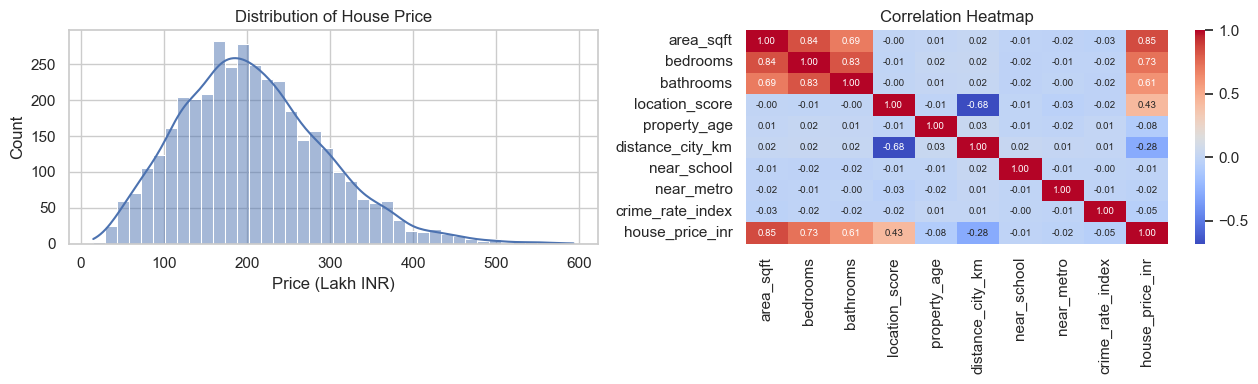

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13,4))
sns.histplot(df['house_price_inr']/1e5, bins=40, kde=True, ax=ax[0]); ax[0].set_title('Distribution of House Price'); ax[0].set_xlabel('Price (Lakh INR)')
sns.heatmap(df.drop(columns=['property_id','sale_date']).corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=ax[1], annot_kws={'size':7})
ax[1].set_title('Correlation Heatmap'); plt.tight_layout(); plt.show()

**Interpretation:** price is right-skewed (a few very expensive houses). Area, location score and bedrooms/bathrooms show the strongest positive link with price; property age, distance from city and crime rate are negative.

### Q6. Identify features and target variable

In [13]:
df['sale_year'] = df['sale_date'].dt.year
TARGET = 'house_price_inr'
FEATURES = ['area_sqft','bedrooms','bathrooms','location_score','property_age',
            'distance_city_km','near_school','near_metro','crime_rate_index','sale_year']
print('Target  :', TARGET); print('Features:', FEATURES)
print('Dropped : property_id (just an identifier), sale_date (replaced by sale_year)')
df['price_lakh'] = df[TARGET]/1e5

Target  : house_price_inr
Features: ['area_sqft', 'bedrooms', 'bathrooms', 'location_score', 'property_age', 'distance_city_km', 'near_school', 'near_metro', 'crime_rate_index', 'sale_year']
Dropped : property_id (just an identifier), sale_date (replaced by sale_year)


### Q7. Train–test split (80/20)

In [14]:
X = df[FEATURES]; y = df['price_lakh']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RS)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (3040, 10)  Test: (760, 10)


### Q8. Basic preprocessing (scaling where required)

Scaling (`StandardScaler`) is **required** for Ridge, Lasso and SVR (penalty / distance based) and **not required** for Decision Tree and Random Forest. The scaler is put **inside a Pipeline**, so during cross-validation it is fitted only on the training folds (no data leakage).

In [15]:
scaler = StandardScaler().fit(X_train)
display(pd.DataFrame(scaler.transform(X_train), columns=FEATURES).describe().loc[['mean','std']].round(2))
def make_scaled(model): return Pipeline([('scaler', StandardScaler()), ('model', model)])
def metrics(model, Xa, ya):
    p = model.predict(Xa); mse = mean_squared_error(ya, p)
    return dict(MSE=mse, MAE=mean_absolute_error(ya, p), RMSE=np.sqrt(mse), R2=r2_score(ya, p))
kf = KFold(5, shuffle=True, random_state=RS)
RESULTS = {} 
def record(name, model, cv_rmse):
    tr, te = metrics(model, X_train, y_train), metrics(model, X_test, y_test)
    RESULTS[name] = {**{f'Train_{k}':v for k,v in tr.items()}, **{f'Test_{k}':v for k,v in te.items()}, 'CV_RMSE': cv_rmse}

,area_sqft,bedrooms,bathrooms,location_score,property_age,distance_city_km,near_school,near_metro,crime_rate_index,sale_year
mean,-0.0,-0.0,0.0,0.0,-0.0,-0.0,-0.0,0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [16]:
base = make_scaled(LinearRegression()).fit(X_train, y_train)
base_cv = -cross_val_score(base, X_train, y_train, cv=kf, scoring='neg_root_mean_squared_error').mean()
record('Linear Regression (baseline)', base, base_cv)
print(RESULTS['Linear Regression (baseline)'])

{'Train_MSE': 616.2585605007077, 'Train_MAE': 18.969290909304974, 'Train_RMSE': np.float64(24.82455559523086), 'Train_R2': 0.9173979319241949, 'Test_MSE': 644.7271977478467, 'Test_MAE': 19.448788028419344, 'Test_RMSE': np.float64(25.391478841293328), 'Test_R2': 0.9199446399359217, 'CV_RMSE': np.float64(24.951408862021314)}


---
# Part C: Regularized Linear Models

### Q9. Ridge Regression (L2)  |  Q10. Lasso Regression (L1)  |  Q11. Tune α using cross-validation

Best Ridge alpha: {'model__alpha': np.float64(2.0433597178569416)} RMSE: 24.9511672175697
Best Lasso alpha: {'model__alpha': np.float64(0.11721022975334805)} RMSE: 24.949309932770024


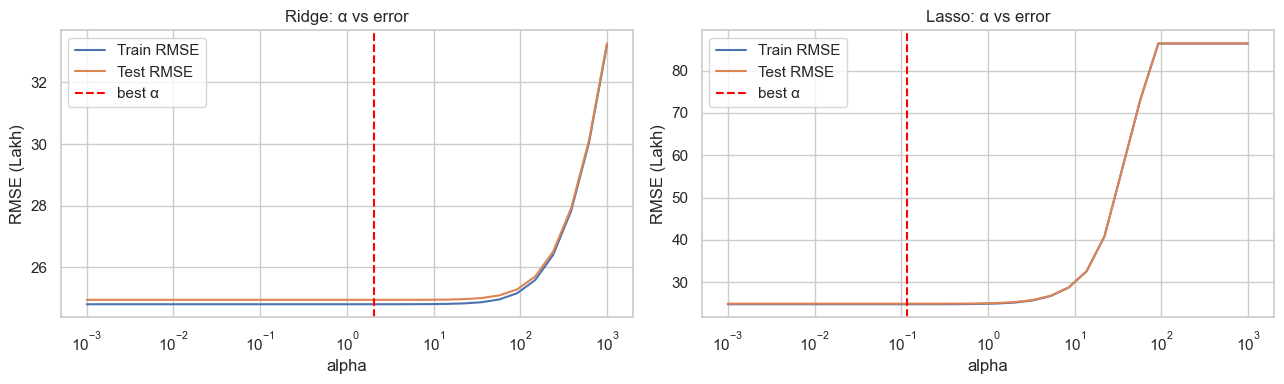

In [17]:
alphas = np.logspace(-3, 3, 30)
ridge_gs = GridSearchCV(make_scaled(Ridge()), {'model__alpha': alphas}, cv=kf, scoring='neg_root_mean_squared_error', return_train_score=True).fit(X_train, y_train)
lasso_gs = GridSearchCV(make_scaled(Lasso(max_iter=20000)), {'model__alpha': alphas}, cv=kf, scoring='neg_root_mean_squared_error', return_train_score=True).fit(X_train, y_train)

print('Best Ridge alpha:', ridge_gs.best_params_, 'RMSE:', -ridge_gs.best_score_)
print('Best Lasso alpha:', lasso_gs.best_params_, 'RMSE:', -lasso_gs.best_score_)

record('Ridge (L2)', ridge_gs.best_estimator_, -ridge_gs.best_score_)
record('Lasso (L1)', lasso_gs.best_estimator_, -lasso_gs.best_score_)

fig, ax = plt.subplots(1, 2, figsize=(13,4))
for a, gs, t in zip(ax, [ridge_gs, lasso_gs], ['Ridge','Lasso']):
    r = pd.DataFrame(gs.cv_results_)
    a.semilogx(alphas, -r['mean_train_score'], label='Train RMSE'); a.semilogx(alphas, -r['mean_test_score'], label='Test RMSE')
    a.axvline(gs.best_params_['model__alpha'], color='red', ls='--', label='best α'); a.set_title(f'{t}: α vs error'); a.set_xlabel('alpha'); a.set_ylabel('RMSE (Lakh)'); a.legend()
    
plt.tight_layout(); plt.show()

**Interpretation:** very large α over-shrinks coefficients (underfitting: both errors rise). Very small α behaves like plain linear regression. The red line is the α with the lowest validation error.

### Q12. Compare Ridge and Lasso: training error, validation error, coefficient behavior

,best alpha,Training RMSE,Validation RMSE,Test RMSE
Ridge,2.0434,24.8247,24.9512,25.3965
Lasso,0.1172,24.8266,24.9493,25.4201


,Linear,Ridge,Lasso
area_sqft,69.560,69.410,69.478
bedrooms,2.899,3.025,2.895
bathrooms,2.723,2.722,2.666
location_score,36.814,36.771,36.747
property_age,-6.503,-6.499,-6.395
distance_city_km,-0.266,-0.294,-0.194
near_school,0.154,0.156,0.034
near_metro,0.526,0.525,0.411
crime_rate_index,-1.405,-1.407,-1.294
sale_year,3.010,3.006,2.895


Lasso made these features zero: []


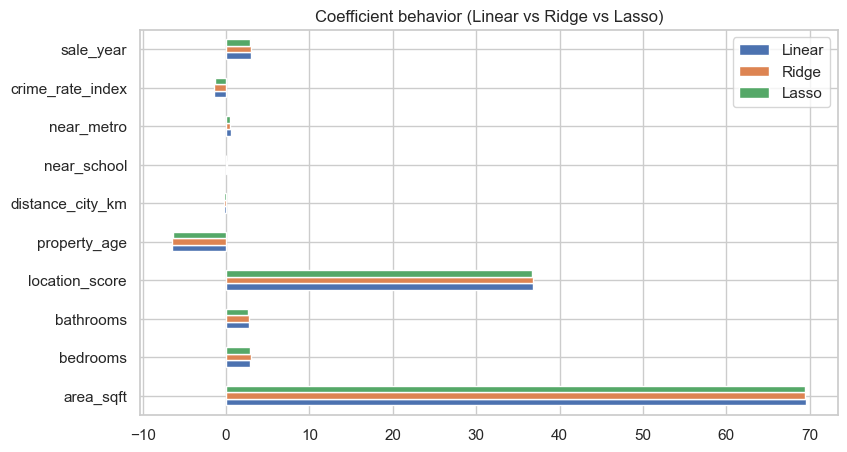

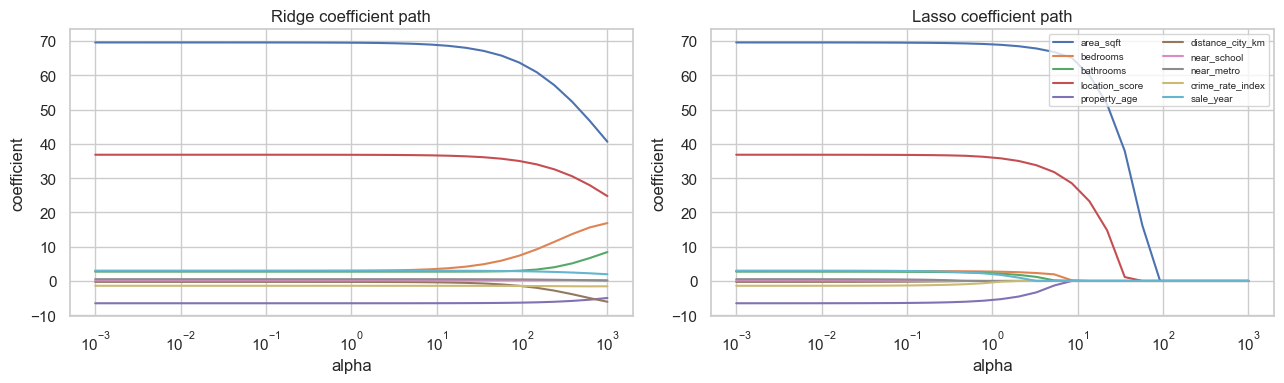

In [18]:
ridge_best = ridge_gs.best_estimator_
lasso_best = lasso_gs.best_estimator_

table = pd.DataFrame({
    'Ridge': [ridge_gs.best_params_['model__alpha'], RESULTS['Ridge (L2)']['Train_RMSE'], -ridge_gs.best_score_, RESULTS['Ridge (L2)']['Test_RMSE']],
    'Lasso': [lasso_gs.best_params_['model__alpha'], RESULTS['Lasso (L1)']['Train_RMSE'], -lasso_gs.best_score_, RESULTS['Lasso (L1)']['Test_RMSE']],
}, index=['best alpha', 'Training RMSE', 'Validation RMSE', 'Test RMSE']).T
display(table.round(4))

coef = pd.DataFrame({
    'Linear': base['model'].coef_,
    'Ridge': ridge_best['model'].coef_,
    'Lasso': lasso_best['model'].coef_,
}, index=FEATURES)
display(coef.round(3))
print('Lasso made these features zero:', list(coef.index[coef['Lasso'] == 0]))

coef.plot.barh(figsize=(9, 5))
plt.title('Coefficient behavior (Linear vs Ridge vs Lasso)')
plt.show()

X_scaled = StandardScaler().fit_transform(X_train)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for i, (Model, name) in enumerate([(Ridge, 'Ridge'), (Lasso, 'Lasso')]):
    paths = []
    for a in alphas:
        paths.append(Model(alpha=a).fit(X_scaled, y_train).coef_)
    ax[i].semilogx(alphas, paths)
    ax[i].set_title(name + ' coefficient path')
    ax[i].set_xlabel('alpha')
    ax[i].set_ylabel('coefficient')
ax[1].legend(FEATURES, fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

**Interpretation:** Ridge shrinks all coefficients smoothly but keeps every feature. Lasso drives weak features to exactly 0 as α grows (feature selection). On this data the dataset has few features and good signal, so both give similar error; Lasso gives a simpler model, Ridge is more stable with correlated features (bedrooms/bathrooms/area).

---
# Part D: Cross-Validation Strategies

### Q13. Apply and compare K-Fold, Stratified K-Fold (binned target), LOOCV, Time Series Split

In [19]:
best_ridge = ridge_gs.best_estimator_
y_bins = pd.qcut(y_train, q=5, labels=False)   
order = X_train['sale_year'].argsort(kind='stable')
Xt, yt = X_train.iloc[order], y_train.iloc[order]

def run_cv(name, cv, Xa, ya, groups=None):
    s = cross_validate(best_ridge, Xa, ya, cv=cv, groups=groups, scoring={'rmse':'neg_root_mean_squared_error','mae':'neg_mean_absolute_error','r2':'r2'})
    return dict(Strategy=name, Folds=len(s['test_rmse']), RMSE_mean=-s['test_rmse'].mean(), RMSE_std=s['test_rmse'].std(), MAE_mean=-s['test_mae'].mean(), R2_mean=s['test_r2'].mean())

rows = [run_cv('K-Fold (k=5)', KFold(5, shuffle=True, random_state=RS), X_train, y_train)]
skf = list(StratifiedKFold(5, shuffle=True, random_state=RS).split(X_train, y_bins))
rows.append(run_cv('Stratified K-Fold (binned target)', skf, X_train, y_train))
rows.append(run_cv('Time Series Split (by sale_year)', TimeSeriesSplit(5), Xt, yt))
loo_pred = np.array([0.0]*len(X_train))

from sklearn.model_selection import cross_val_predict
loo_pred = cross_val_predict(best_ridge, X_train, y_train, cv=LeaveOneOut(), n_jobs=-1)
err = y_train.values - loo_pred
rows.append(dict(Strategy='Leave-One-Out (LOOCV)', Folds=len(y_train), RMSE_mean=np.sqrt((err**2).mean()), RMSE_std=np.nan, MAE_mean=np.abs(err).mean(), R2_mean=r2_score(y_train, loo_pred)))
cv_table = pd.DataFrame(rows).set_index('Strategy'); display(cv_table.round(4))

,Folds,RMSE_mean,RMSE_std,MAE_mean,R2_mean
Strategy,,,,,
K-Fold (k=5),5,24.9512,0.8898,19.0663,0.9163
Stratified K-Fold (binned target),5,24.8988,0.7881,19.0315,0.9168
Time Series Split (by sale_year),5,24.8503,0.9188,18.9482,0.9167
Leave-One-Out (LOOCV),3040,24.9230,NaN,19.0387,0.9167


Note: with LOOCV every fold has 1 sample, so R²/RMSE are computed on all pooled predictions (fold-wise std is not defined).

### Q14. Analyze how performance metrics vary across CV strategies

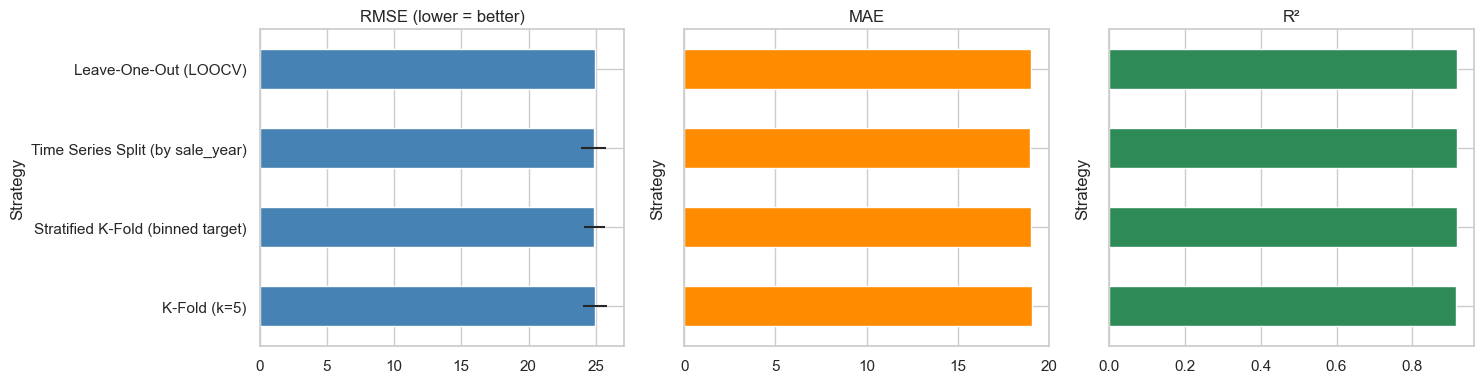

TimeSeriesSplit fold-wise RMSE: [26.159 25.12  23.295 24.931 24.748]


In [20]:
fig, ax = plt.subplots(1, 3, figsize=(15,4))
cv_table['RMSE_mean'].plot.barh(ax=ax[0], xerr=cv_table['RMSE_std'].fillna(0), color='steelblue'); ax[0].set_title('RMSE (lower = better)')
cv_table['MAE_mean'].plot.barh(ax=ax[1], color='darkorange'); ax[1].set_title('MAE'); ax[1].set_yticklabels([])
cv_table['R2_mean'].plot.barh(ax=ax[2], color='seagreen'); ax[2].set_title('R²'); ax[2].set_yticklabels([])
plt.tight_layout(); plt.show()

ts = [np.sqrt(mean_squared_error(yt.iloc[te], best_ridge.fit(Xt.iloc[tr], yt.iloc[tr]).predict(Xt.iloc[te]))) for tr, te in TimeSeriesSplit(5).split(Xt)]
print('TimeSeriesSplit fold-wise RMSE:', np.round(ts, 3))

**Analysis:** K-Fold, Stratified K-Fold and LOOCV give almost the same score (shuffled data = same distribution). Stratified K-Fold has slightly lower fold-to-fold spread because every fold covers all price ranges. LOOCV is nearly unbiased but needs N model fits (slow for big models). Time Series Split differs because it trains only on the past, uses less data in early folds and tests on later years – it is the most realistic check if the model will predict future sales. **Decision:** use 5-Fold CV for tuning (fast, stable) and Time Series Split as an extra check.

---
# Part E: Tree-Based Regression Models

### Q15. Decision Tree Regression  |  Q16. Control complexity (max_depth, min_samples)

Unpruned tree  Train R2: 1.0000 | Test R2: 0.8692 | depth=21 | leaves=3040
Best DT params: {'max_depth': 8, 'min_samples_leaf': 20, 'min_samples_split': 2}  CV RMSE: 27.331192417633115


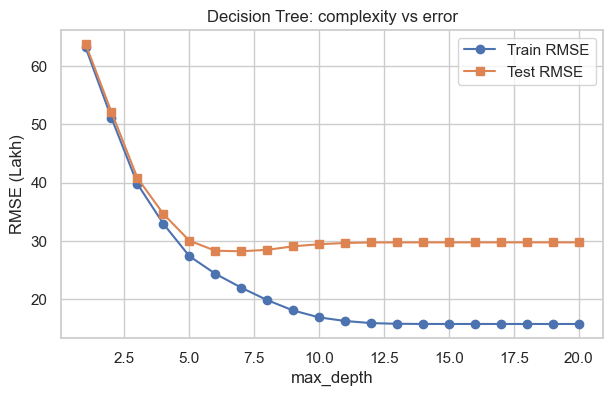

In [21]:
full_tree = DecisionTreeRegressor(random_state=RS).fit(X_train, y_train)
print('Unpruned tree  Train R2: %.4f | Test R2: %.4f | depth=%d | leaves=%d' % (full_tree.score(X_train,y_train), full_tree.score(X_test,y_test), full_tree.get_depth(), full_tree.get_n_leaves()))
dt_gs = GridSearchCV(DecisionTreeRegressor(random_state=RS),
    {'max_depth':[2,3,4,5,6,8,10,None], 'min_samples_split':[2,10,30], 'min_samples_leaf':[1,5,10,20,40]},
    cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1).fit(X_train, y_train)
print('Best DT params:', dt_gs.best_params_, ' CV RMSE:', -dt_gs.best_score_)
record('Decision Tree (tuned)', dt_gs.best_estimator_, -dt_gs.best_score_)
record('Decision Tree (unpruned)', full_tree, -cross_val_score(full_tree, X_train, y_train, cv=kf, scoring='neg_root_mean_squared_error').mean())

dep = range(1, 21); tr_e, va_e = [], []
for d in dep:
    m = DecisionTreeRegressor(max_depth=d, min_samples_leaf=5, random_state=RS)
    tr_e.append(np.sqrt(mean_squared_error(y_train, m.fit(X_train, y_train).predict(X_train))))
    va_e.append(-cross_val_score(m, X_train, y_train, cv=kf, scoring='neg_root_mean_squared_error').mean())
plt.figure(figsize=(7,4)); plt.plot(dep, tr_e, 'o-', label='Train RMSE'); plt.plot(dep, va_e, 's-', label='Test RMSE')
plt.xlabel('max_depth'); plt.ylabel('RMSE (Lakh)'); plt.title('Decision Tree: complexity vs error'); plt.legend(); plt.show()

**Interpretation:** the unpruned tree memorizes the training set (train R² ≈ 1, much lower on test) = overfitting. Limiting `max_depth` and increasing `min_samples_leaf` makes the tree simpler and the validation error drops. Very small depth underfits.

### Q17. Random Forest Regression

Best RF params: {'max_depth': None, 'max_features': 0.6, 'min_samples_leaf': 3, 'n_estimators': 150} RMSE: 23.569817398847594


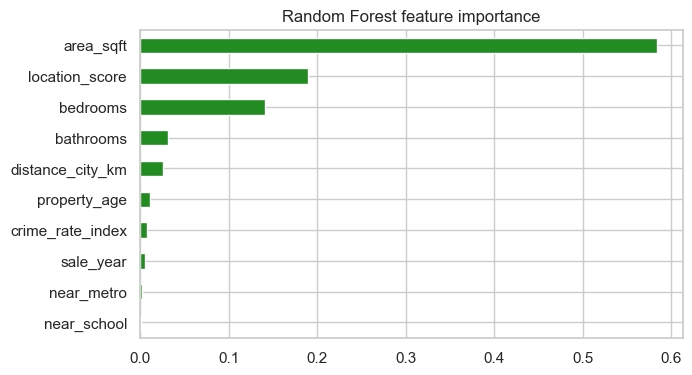

In [22]:
rf_gs = GridSearchCV(RandomForestRegressor(random_state=RS),
    {'n_estimators':[150], 'max_depth':[10,None], 'min_samples_leaf':[1,3,5], 'max_features':[0.6,1.0]},
    cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1).fit(X_train, y_train)
print('Best RF params:', rf_gs.best_params_, 'RMSE:', -rf_gs.best_score_)
record('Random Forest (tuned)', rf_gs.best_estimator_, -rf_gs.best_score_)
imp = pd.Series(rf_gs.best_estimator_.feature_importances_, index=FEATURES).sort_values()
imp.plot.barh(figsize=(7,4), color='forestgreen'); plt.title('Random Forest feature importance'); plt.show()

### Q18. Compare single tree vs ensemble

,Train_RMSE,Test_RMSE,Train_R2,Test_R2,CV_RMSE
Decision Tree (unpruned),0.0000,32.4529,1.0000,0.8692,33.8274
Decision Tree (tuned),22.9116,27.3488,0.9296,0.9071,27.3312
Random Forest (tuned),13.6275,23.8732,0.9751,0.9292,23.5698


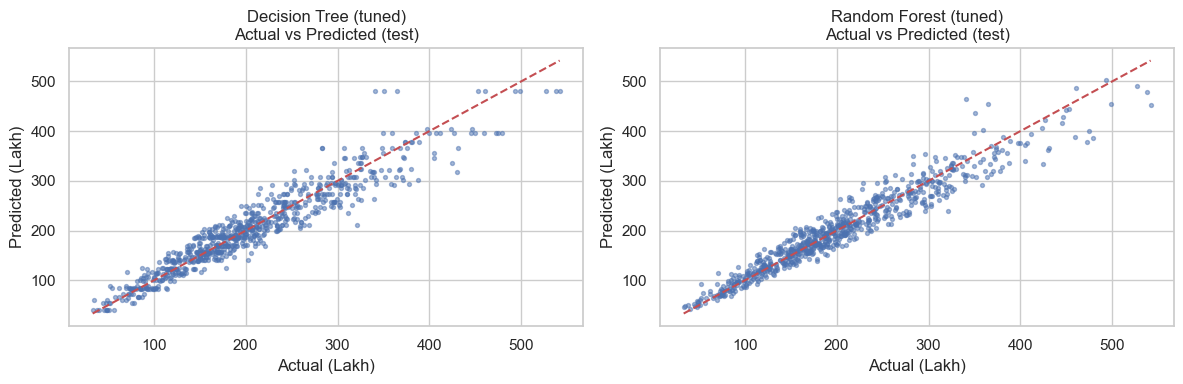

In [23]:
display(pd.DataFrame(RESULTS).T.loc[['Decision Tree (unpruned)','Decision Tree (tuned)','Random Forest (tuned)'], ['Train_RMSE','Test_RMSE','Train_R2','Test_R2','CV_RMSE']].round(4))
fig, ax = plt.subplots(1, 2, figsize=(12,4))

for a, (n, m) in zip(ax, {'Decision Tree (tuned)': dt_gs.best_estimator_, 'Random Forest (tuned)': rf_gs.best_estimator_}.items()):
    p = m.predict(X_test); a.scatter(y_test, p, s=8, alpha=.5); lim = [y_test.min(), y_test.max()]; a.plot(lim, lim, 'r--')
    a.set_title(f'{n}\nActual vs Predicted (test)'); a.set_xlabel('Actual (Lakh)'); a.set_ylabel('Predicted (Lakh)')
    
plt.tight_layout(); plt.show()

**Interpretation:** the Random Forest averages many de-correlated trees, which reduces variance, so its test error is lower and more stable than a single tree. The single tree is easier to explain but less accurate.

---
# Part F: Support Vector Regression

### Q19. Implement SVR (Linear kernel and Polynomial/RBF kernel)

SVR is distance-based, so features are scaled in the pipeline. The target (Lakh INR) is also standardized with `TransformedTargetRegressor`, otherwise ε and C are not on a comparable scale.

In [24]:
def svr_pipe(**kw): return TransformedTargetRegressor(regressor=make_scaled(SVR(**kw)), transformer=StandardScaler())
svr_lin = svr_pipe(kernel='linear').fit(X_train, y_train)
svr_rbf = svr_pipe(kernel='rbf').fit(X_train, y_train)
print('Default SVR Linear  Test R2: %.4f' % svr_lin.score(X_test, y_test)); print('Default SVR RBF     Test R2: %.4f' % svr_rbf.score(X_test, y_test))

Default SVR Linear  Test R2: 0.9186
Default SVR RBF     Test R2: 0.9242


### Q20. Tune hyperparameters (C, γ, ε)

Best SVR-Linear: {'regressor__model__C': 1, 'regressor__model__epsilon': 0.2}  CV RMSE: 24.958476819261808
Best SVR-RBF   : {'regressor__model__C': 1, 'regressor__model__epsilon': 0.05, 'regressor__model__gamma': 0.03}  CV RMSE: 22.684503421527495


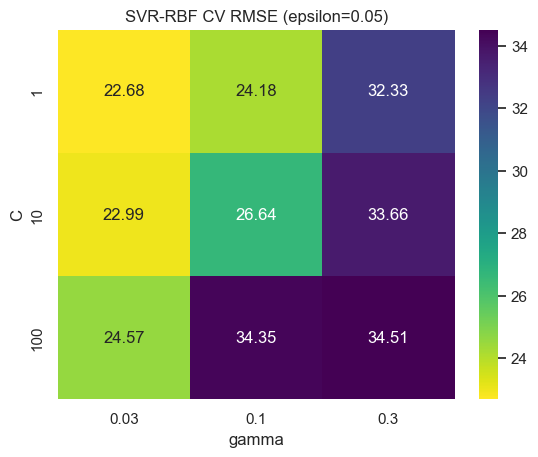

In [25]:
kf3 = KFold(5, shuffle=True, random_state=RS)

lin_gs = GridSearchCV(svr_pipe(kernel='linear'), {'regressor__model__C':[0.1,1,10], 'regressor__model__epsilon':[0.05,0.2]},
                      cv=kf3, scoring='neg_root_mean_squared_error', n_jobs=-1).fit(X_train, y_train)

rbf_gs = GridSearchCV(svr_pipe(kernel='rbf'), {'regressor__model__C':[1,10,100], 'regressor__model__gamma':[0.03,0.1,0.3], 'regressor__model__epsilon':[0.05,0.2]},
                      cv=kf3, scoring='neg_root_mean_squared_error', n_jobs=-1).fit(X_train, y_train)

print('Best SVR-Linear:', lin_gs.best_params_, ' CV RMSE:', -lin_gs.best_score_)
print('Best SVR-RBF   :', rbf_gs.best_params_, ' CV RMSE:', -rbf_gs.best_score_)
record('SVR Linear (tuned)', lin_gs.best_estimator_, -lin_gs.best_score_); record('SVR RBF (tuned)', rbf_gs.best_estimator_, -rbf_gs.best_score_)

r = pd.DataFrame(rbf_gs.cv_results_); eps = rbf_gs.best_params_['regressor__model__epsilon']
pv = r[r['param_regressor__model__epsilon']==eps].pivot(index='param_regressor__model__C', columns='param_regressor__model__gamma', values='mean_test_score')*-1
sns.heatmap(pv.astype(float), annot=True, fmt='.2f', cmap='viridis_r'); plt.title(f'SVR-RBF CV RMSE (epsilon={eps})'); plt.xlabel('gamma'); plt.ylabel('C'); plt.show()

**Interpretation:** C = penalty for errors (large C → complex/tight fit), γ = reach of one sample in the RBF kernel (large γ → wiggly/overfit), ε = width of the no-penalty tube. The heatmap shows the best (darkest) C/γ combination.

### Q21. Compare SVR performance with linear and tree-based models

In [26]:
res = pd.DataFrame(RESULTS).T

models = ['Linear Regression (baseline)', 'Ridge (L2)', 'Lasso (L1)',
          'Decision Tree (tuned)', 'Random Forest (tuned)',
          'SVR Linear (tuned)', 'SVR RBF (tuned)']
columns = ['Test_RMSE', 'Test_MAE', 'Test_R2', 'CV_RMSE']

display(res.loc[models, columns].round(4))

,Test_RMSE,Test_MAE,Test_R2,CV_RMSE
Linear Regression (baseline),25.3915,19.4488,0.9199,24.9514
Ridge (L2),25.3965,19.4463,0.9199,24.9512
Lasso (L1),25.4201,19.4611,0.9198,24.9493
Decision Tree (tuned),27.3488,20.2227,0.9071,27.3312
Random Forest (tuned),23.8732,17.5312,0.9292,23.5698
SVR Linear (tuned),25.5235,19.4472,0.9191,24.9585
SVR RBF (tuned),22.7372,16.6468,0.9358,22.6845


**Interpretation:** SVR with a linear kernel behaves like the regularized linear models. The RBF kernel can capture non-linear price patterns, so it competes with (or beats) the linear models; compare its numbers with Random Forest in the table above.

---
# Part G: Model Comparison & Evaluation

### Q22. Evaluate all models using MSE, MAE, RMSE, R²

,Train_MSE,Test_MSE,Train_MAE,Test_MAE,Train_RMSE,Test_RMSE,Train_R2,Test_R2,CV_RMSE
SVR RBF (tuned),459.5942,516.9819,15.7768,16.6468,21.4381,22.7372,0.9384,0.9358,22.6845
Random Forest (tuned),185.7087,569.9281,10.0231,17.5312,13.6275,23.8732,0.9751,0.9292,23.5698
Linear Regression (baseline),616.2586,644.7272,18.9693,19.4488,24.8246,25.3915,0.9174,0.9199,24.9514
Ridge (L2),616.2664,644.9833,18.9672,19.4463,24.8247,25.3965,0.9174,0.9199,24.9512
Lasso (L1),616.3590,646.1838,18.9543,19.4611,24.8266,25.4201,0.9174,0.9198,24.9493
SVR Linear (tuned),618.4824,651.4472,18.9011,19.4472,24.8693,25.5235,0.9171,0.9191,24.9585
Decision Tree (tuned),524.9403,747.9551,17.1936,20.2227,22.9116,27.3488,0.9296,0.9071,27.3312


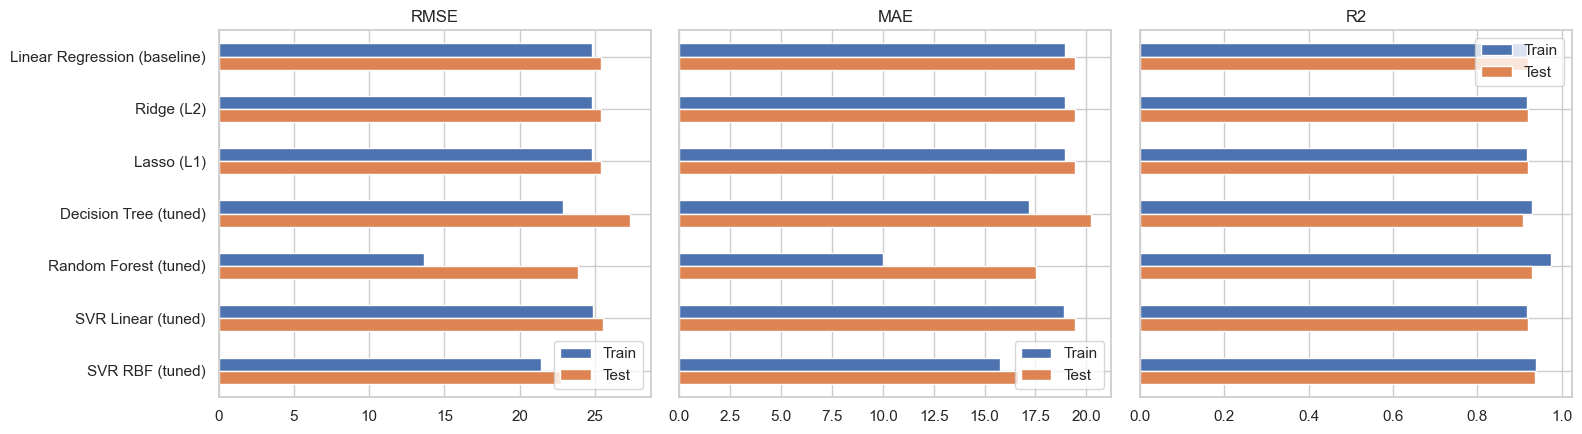

In [27]:
MODELS = ['Linear Regression (baseline)','Ridge (L2)','Lasso (L1)','Decision Tree (tuned)','Random Forest (tuned)','SVR Linear (tuned)','SVR RBF (tuned)']

res = pd.DataFrame(RESULTS).T.loc[MODELS]

order_cols = ['Train_MSE','Test_MSE','Train_MAE','Test_MAE','Train_RMSE','Test_RMSE','Train_R2','Test_R2','CV_RMSE']

display(res[order_cols].round(4).sort_values('Test_RMSE'))

fig, ax = plt.subplots(1, 3, figsize=(16,4.5))
for a, m in zip(ax, ['RMSE','MAE','R2']):
    d = res[[f'Train_{m}', f'Test_{m}']].astype(float); d.columns=['Train','Test']; d.plot.barh(ax=a); a.set_title(m); a.invert_yaxis()
    if a is not ax[0]: a.set_yticklabels([])
plt.tight_layout(); plt.show()

### Q23. Compare Regularized Linear Models vs Tree-Based Models vs SVR

,Test_RMSE,Test_MAE,Test_R2
"Regularized Linear (Ridge, Lasso)",25.4083,19.4537,0.9198
"Tree-Based (DT, RF)",25.6110,18.8769,0.9182
"SVR (Linear, RBF)",24.1303,18.0470,0.9275


Best model by cross-validated RMSE: SVR RBF (tuned)


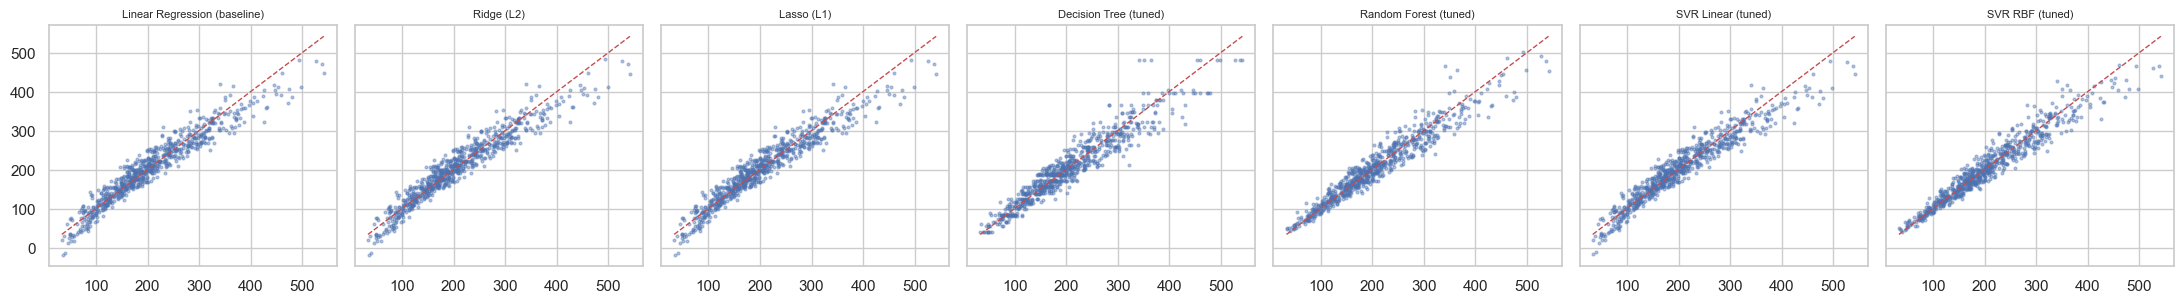

In [28]:
groups = {'Regularized Linear (Ridge, Lasso)': ['Ridge (L2)','Lasso (L1)'], 'Tree-Based (DT, RF)': ['Decision Tree (tuned)','Random Forest (tuned)'], 'SVR (Linear, RBF)': ['SVR Linear (tuned)','SVR RBF (tuned)']}

g = pd.DataFrame({k: res.loc[v, ['Test_RMSE','Test_MAE','Test_R2']].astype(float).mean() for k, v in 
                  groups.items()}).T; display(g.round(4))

best_name = res['CV_RMSE'].astype(float).idxmin(); print('Best model by cross-validated RMSE:', best_name)

fig, ax = plt.subplots(1, len(MODELS), figsize=(22,3.2), sharey=True)

fitted = {'Linear Regression (baseline)': base, 'Ridge (L2)': ridge_gs.best_estimator_, 'Lasso (L1)': 
lasso_gs.best_estimator_, 'Decision Tree (tuned)': dt_gs.best_estimator_,
          'Random Forest (tuned)': rf_gs.best_estimator_, 'SVR Linear (tuned)': lin_gs.best_estimator_, 'SVR RBF (tuned)': rbf_gs.best_estimator_}

for a, n in zip(ax, MODELS):
    p = fitted[n].predict(X_test); a.scatter(y_test, p, s=4, alpha=.4); lim=[y_test.min(), y_test.max()]; a.plot(lim, lim, 'r--', lw=1); a.set_title(n, fontsize=8)

plt.tight_layout(); plt.show()

### Q24. Signs of overfitting / underfitting in each model

,Train_R2,Test_R2,Train_RMSE,Test_RMSE,CV_RMSE,R2_gap,Diagnosis
Linear Regression (baseline),0.9174,0.9199,24.8246,25.3915,24.9514,-0.0025,"Good fit (small gap, high R2)"
Ridge (L2),0.9174,0.9199,24.8247,25.3965,24.9512,-0.0025,"Good fit (small gap, high R2)"
Lasso (L1),0.9174,0.9198,24.8266,25.4201,24.9493,-0.0024,"Good fit (small gap, high R2)"
Decision Tree (tuned),0.9296,0.9071,22.9116,27.3488,27.3312,0.0225,"Good fit (small gap, high R2)"
Random Forest (tuned),0.9751,0.9292,13.6275,23.8732,23.5698,0.0459,"Good fit (small gap, high R2)"
SVR Linear (tuned),0.9171,0.9191,24.8693,25.5235,24.9585,-0.0020,"Good fit (small gap, high R2)"
SVR RBF (tuned),0.9384,0.9358,21.4381,22.7372,22.6845,0.0026,"Good fit (small gap, high R2)"


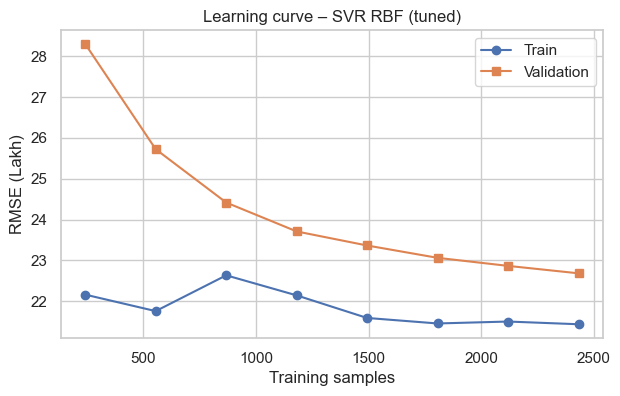

In [29]:
d = res[['Train_R2','Test_R2','Train_RMSE','Test_RMSE','CV_RMSE']].astype(float).copy()
d['R2_gap'] = d['Train_R2'] - d['Test_R2']
def diag(r):
    if r['R2_gap'] > 0.08: return 'Overfitting (train >> test)'
    if r['Test_R2'] < 0.6: return 'Underfitting (low R2 on both)'
    return 'Good fit (small gap, high R2)'
d['Diagnosis'] = d.apply(diag, axis=1); display(d.round(4))

tr_sz, trs, vas = learning_curve(fitted[best_name], X_train, y_train, cv=kf, scoring='neg_root_mean_squared_error', train_sizes=np.linspace(.1,1,8), n_jobs=-1)
plt.figure(figsize=(7,4)); plt.plot(tr_sz, -trs.mean(1), 'o-', label='Train'); plt.plot(tr_sz, -vas.mean(1), 's-', label='Validation')
plt.title(f'Learning curve – {best_name}'); plt.xlabel('Training samples'); plt.ylabel('RMSE (Lakh)'); plt.legend(); plt.show()

**Diagnosis summary:** the unpruned tree (Part E) is the textbook overfit. Untuned / weakly-regularized models and the tuned linear models show a small train–test gap (good generalization). Models with low R² on both sets would indicate underfitting. See the `Diagnosis` column above.

---
# Part H: Final Analysis & Reporting

### Q25. Final report

In [30]:
from IPython.display import Markdown
bm = res.loc[best_name].astype(float); bl = res.loc['Linear Regression (baseline)'].astype(float)
lin_best = res.loc[['Ridge (L2)','Lasso (L1)','SVR Linear (tuned)']]['Test_RMSE'].astype(float).idxmin()
nl_best  = res.loc[['Decision Tree (tuned)','Random Forest (tuned)','SVR RBF (tuned)']]['Test_RMSE'].astype(float).idxmin()
sd = y_test.std(); ALL = pd.DataFrame(RESULTS).T
display(Markdown(f'''
**1. Best-performing model and justification:** **{best_name}** has the lowest cross-validated RMSE ({bm['CV_RMSE']:.2f} Lakh). On unseen test data: RMSE = {bm['Test_RMSE']:.2f} Lakh, MAE = {bm['Test_MAE']:.2f} Lakh, R² = {bm['Test_R2']:.4f}. Train R² = {bm['Train_R2']:.4f}, so the train–test gap is {bm['Train_R2']-bm['Test_R2']:.4f} (small gap = generalizes well).

**2. Impact of regularization:** baseline Linear Regression CV RMSE = {bl['CV_RMSE']:.3f}; Ridge = {res.loc['Ridge (L2)','CV_RMSE']:.3f}; Lasso = {res.loc['Lasso (L1)','CV_RMSE']:.3f} Lakh. Tuned α keeps coefficients small and stable. Lasso removed {int((coef['Lasso']==0).sum())} feature(s) completely. Regularization helps most when features are correlated or data is small; here the dataset is large so the gain is modest but the model is more stable. For trees, the same idea is done by limiting depth / leaf size (unpruned tree test R² = {ALL.loc['Decision Tree (unpruned)','Test_R2']:.3f} vs tuned {res.loc['Decision Tree (tuned)','Test_R2']:.3f}).

**3. Role of cross-validation in model stability:** all hyperparameters (α, depth, C, γ, ε) were chosen using 5-fold CV on the training set only, so the test set stayed untouched. Different CV strategies gave consistent RMSE (see Part D table: {cv_table['RMSE_mean'].min():.2f}–{cv_table['RMSE_mean'].max():.2f} Lakh), which shows the estimate is stable and not dependent on one lucky split.

**4. Linear vs non-linear regressors:** best linear/regularized model = **{lin_best}** (Test RMSE {res.loc[lin_best,'Test_RMSE']:.2f}); best non-linear model = **{nl_best}** (Test RMSE {res.loc[nl_best,'Test_RMSE']:.2f}). {'Non-linear models capture interactions between features (e.g. area × location) and win.' if res.loc[nl_best,'Test_RMSE'] < res.loc[lin_best,'Test_RMSE'] else 'Linear models are already enough: the price relation is mostly linear, so extra complexity does not help.'}

**5. Business interpretation:** the typical prediction error (MAE) is about **₹{bm['Test_MAE']*1e5:,.0f}** per house, i.e. about {bm['Test_MAE']/y_test.mean()*100:.1f}% of the average price (₹{y_test.mean()*1e5:,.0f}). The model explains {bm['Test_R2']*100:.1f}% of price variation, so it is reliable for valuation support, listing-price suggestions and spotting over/under-priced properties. Top price drivers: {', '.join(imp.sort_values(ascending=False).index[:3])}. It should be re-trained regularly because market prices change over time.
'''))


**1. Best-performing model and justification:** **SVR RBF (tuned)** has the lowest cross-validated RMSE (22.68 Lakh). On unseen test data: RMSE = 22.74 Lakh, MAE = 16.65 Lakh, R² = 0.9358. Train R² = 0.9384, so the train–test gap is 0.0026 (small gap = generalizes well).

**2. Impact of regularization:** baseline Linear Regression CV RMSE = 24.951; Ridge = 24.951; Lasso = 24.949 Lakh. Tuned α keeps coefficients small and stable. Lasso removed 0 feature(s) completely. Regularization helps most when features are correlated or data is small; here the dataset is large so the gain is modest but the model is more stable. For trees, the same idea is done by limiting depth / leaf size (unpruned tree test R² = 0.869 vs tuned 0.907).

**3. Role of cross-validation in model stability:** all hyperparameters (α, depth, C, γ, ε) were chosen using 5-fold CV on the training set only, so the test set stayed untouched. Different CV strategies gave consistent RMSE (see Part D table: 24.85–24.95 Lakh), which shows the estimate is stable and not dependent on one lucky split.

**4. Linear vs non-linear regressors:** best linear/regularized model = **Ridge (L2)** (Test RMSE 25.40); best non-linear model = **SVR RBF (tuned)** (Test RMSE 22.74). Non-linear models capture interactions between features (e.g. area × location) and win.

**5. Business interpretation:** the typical prediction error (MAE) is about **₹1,664,678** per house, i.e. about 8.1% of the average price (₹20,536,069). The model explains 93.6% of price variation, so it is reliable for valuation support, listing-price suggestions and spotting over/under-priced properties. Top price drivers: area_sqft, location_score, bedrooms. It should be re-trained regularly because market prices change over time.


### Q26. saved model

In [31]:
final_model = fitted[best_name]
final_model.fit(X_train, y_train)
joblib.dump(final_model, 'final_model.joblib')
res[order_cols].round(4).to_csv('model_comparison.csv')
cv_table.round(4).to_csv('cv_strategies.csv')
meta = {'best_model': best_name, 'features': FEATURES, 'target_unit': 'Lakh INR (1 Lakh = 100000 INR)',
        'test_metrics': {k: float(bm[f'Test_{k}']) for k in ['MSE','MAE','RMSE','R2']},
        'feature_ranges': {c: [float(X[c].min()), float(X[c].max()), float(X[c].median())] for c in FEATURES},
        'importance': imp.sort_values(ascending=False).to_dict()}
json.dump(meta, open('model_meta.json','w'), indent=2)
print('Saved: final_model.joblib, model_comparison.csv, cv_strategies.csv, model_meta.json')

Saved: final_model.joblib, model_comparison.csv, cv_strategies.csv, model_meta.json
